# Logistic Regression with Python
**IBM Machine Learning with Python Lab**

Estimated time needed: **30 minutes**

---

### Objectives
After completing this lab you will be able to:
- Use Logistic Regression for classification
- Preprocess data for modeling
- Implement Logistic regression on real world data

### Install and import the required libraries
Make sure the required libraries are available by executing the cell below.

In [1]:
# Make sure the required libraries are available
# !pip install numpy==2.2.0 !pip install pandas==2.2.3 !pip install scikit-learn==1.6.0 !pip install matplotlib==3.9.3

Let's first import required libraries:

In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import log_loss
import matplotlib.pyplot as plt

%matplotlib inline

import warnings
warnings.filterwarnings('ignore')

# Classification with Logistic Regression

### Scenario
Assume that you are working for a telecommunications company which is concerned about the number of customers leaving their land-line business for cable competitors. They need to understand who is more likely to leave the company.

### Load the Telco Churn data
Telco Churn is a hypothetical data file that concerns a telecommunications company's efforts to reduce turnover in its customer base. Each case corresponds to a separate customer and it records various demographic and service usage information. Before you can work with the data, you must use the URL to get the ChurnData.csv.

### About the dataset
We will use a telecommunications dataset for predicting customer churn. This is a historical customer dataset where each row represents one customer. The data is relatively easy to understand, and you may uncover insights you can use immediately. Typically it is less expensive to keep customers than acquire new ones, so the focus of this analysis is to predict the customers who will stay with the company. This data set provides you information about customer preferences, services opted, personal details, etc. which helps you predict customer churn.

### Load Data from URL

In [3]:
# churn_df = pd.read_csv("ChurnData.csv")
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML0101EN-SkillsNetwork/labs/Module%203/data/ChurnData.csv"
churn_df = pd.read_csv(url)

churn_df

,tenure,age,address,income,ed,employ,equip,callcard,wireless,longmon,...,pager,internet,callwait,confer,ebill,loglong,logtoll,lninc,custcat,churn
0,11.0,33.0,7.0,136.0,5.0,5.0,0.0,1.0,1.0,4.40,...,1.0,0.0,1.0,1.0,0.0,1.482,3.033,4.913,4.0,1.0
1,33.0,33.0,12.0,33.0,2.0,0.0,0.0,0.0,0.0,9.45,...,0.0,0.0,0.0,0.0,0.0,2.246,3.240,3.497,1.0,1.0
2,23.0,30.0,9.0,30.0,1.0,2.0,0.0,0.0,0.0,6.30,...,0.0,0.0,0.0,1.0,0.0,1.841,3.240,3.401,3.0,0.0
3,38.0,35.0,5.0,76.0,2.0,10.0,1.0,1.0,1.0,6.05,...,1.0,1.0,1.0,1.0,1.0,1.800,3.807,4.331,4.0,0.0
4,7.0,35.0,14.0,80.0,2.0,15.0,0.0,1.0,0.0,7.10,...,0.0,0.0,1.0,1.0,0.0,1.960,3.091,4.382,3.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,55.0,44.0,24.0,83.0,1.0,23.0,0.0,1.0,0.0,17.35,...,0.0,0.0,0.0,1.0,0.0,2.854,3.199,4.419,3.0,0.0
196,34.0,23.0,3.0,24.0,1.0,7.0,0.0,1.0,0.0,6.00,...,0.0,0.0,1.0,1.0,0.0,1.792,3.332,3.178,3.0,0.0
197,6.0,32.0,10.0,47.0,1.0,10.0,0.0,1.0,0.0,3.85,...,0.0,0.0,1.0,1.0,0.0,1.348,3.168,3.850,3.0,0.0
198,24.0,30.0,0.0,25.0,4.0,5.0,0.0,1.0,1.0,8.70,...,1.0,1.0,1.0,1.0,1.0,2.163,3.866,3.219,4.0,1.0


## Data Preprocessing

Let's select some features for the modeling. Also, we change the target data type to be an integer, as it is a requirement by the scikit-learn algorithm:

For this lab, we can use a subset of the fields available to develop out model. Let us assume that the fields we use are 'tenure', 'age', 'address', 'income', 'ed', 'employ', 'equip' and of course 'churn'.

In [4]:
churn_df = churn_df[['tenure', 'age', 'address', 'income', 'ed', 'employ', 'equip', 'churn']]
churn_df['churn'] = churn_df['churn'].astype('int')
churn_df

,tenure,age,address,income,ed,employ,equip,churn
0,11.0,33.0,7.0,136.0,5.0,5.0,0.0,1
1,33.0,33.0,12.0,33.0,2.0,0.0,0.0,1
2,23.0,30.0,9.0,30.0,1.0,2.0,0.0,0
3,38.0,35.0,5.0,76.0,2.0,10.0,1.0,0
4,7.0,35.0,14.0,80.0,2.0,15.0,0.0,0
...,...,...,...,...,...,...,...,...
195,55.0,44.0,24.0,83.0,1.0,23.0,0.0,0
196,34.0,23.0,3.0,24.0,1.0,7.0,0.0,0
197,6.0,32.0,10.0,47.0,1.0,10.0,0.0,0
198,24.0,30.0,0.0,25.0,4.0,5.0,0.0,1


For modeling the input fields X and the target field y need to be fixed. Since that the target to be predicted is 'churn', the data under this field will be stored under the variable 'y'. We may use any combination or all of the remaining fields as the input. Store these values in the variable 'X'.

In [5]:
X = np.asarray(churn_df[['tenure', 'age', 'address', 'income', 'ed', 'employ', 'equip']])
X[0:5] #print the first 5 values

array([[ 11.,  33.,   7., 136.,   5.,   5.,   0.],
       [ 33.,  33.,  12.,  33.,   2.,   0.,   0.],
       [ 23.,  30.,   9.,  30.,   1.,   2.,   0.],
       [ 38.,  35.,   5.,  76.,   2.,  10.,   1.],
       [  7.,  35.,  14.,  80.,   2.,  15.,   0.]])

In [6]:
y = np.asarray(churn_df['churn'])
y[0:5] #print the first 5 values

array([1, 1, 0, 0, 0])

It is also a norm to standardize or normalize the dataset in order to have all the features at the same scale. This helps the model learn faster and improves the model performance. We may make use of StandardScalar function in the Scikit-Learn library.

In [7]:
X_norm = StandardScaler().fit(X).transform(X)
X_norm[0:5]

array([[-1.13518441, -0.62595491, -0.4588971 ,  0.4751423 ,  1.6961288 ,
        -0.58477841, -0.85972695],
       [-0.11604313, -0.62595491,  0.03454064, -0.32886061, -0.6433592 ,
        -1.14437497, -0.85972695],
       [-0.57928917, -0.85594447, -0.261522  , -0.35227817, -1.42318853,
        -0.92053635, -0.85972695],
       [ 0.11557989, -0.47262854, -0.65627219,  0.00679109, -0.6433592 ,
        -0.02518185,  1.16316   ],
       [-1.32048283, -0.47262854,  0.23191574,  0.03801451, -0.6433592 ,
         0.53441472, -0.85972695]])

## Splitting the dataset

The trained model has to be tested and evaluated on data which has not been used during training. Therefore, it is required to separate a part of the data for testing and the remaining for training. For this, we may make use of the train_test_split function in the scikit-learn library.

In [8]:
X_train, X_test, y_train, y_test = train_test_split( X_norm, y, test_size=0.2, random_state=4)

## Logistic Regression Classifier modeling

Let's build the model using LogisticRegression from the Scikit-learn package and fit our model with train data set.

In [9]:
LR = LogisticRegression().fit(X_train,y_train)

Fitting, or in simple terms training, gives us a model that has now learnt from the traning data and can be used to predict the output variable. Let us predict the churn parameter for the test data set.

In [10]:
yhat = LR.predict(X_test)
yhat[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 1, 0])

To understand this prediction, we can also have a look at the prediction probability of data point of the test data set. Use the function predict_proba , we can get the probability of each class. The first column is the probability of the record belonging to class 0, and second column that of class 1. Note that the class prediction system uses the threshold for class prediction as 0.5. This means that the class predicted is the one which is most likely.

In [11]:
yhat_prob = LR.predict_proba(X_test)
yhat_prob[:10]

array([[0.74643946, 0.25356054],
       [0.92667894, 0.07332106],
       [0.83442627, 0.16557373],
       [0.94600618, 0.05399382],
       [0.84325532, 0.15674468],
       [0.71448367, 0.28551633],
       [0.77076426, 0.22923574],
       [0.90955642, 0.09044358],
       [0.26152115, 0.73847885],
       [0.94900731, 0.05099269]])

Since the purpose here is to predict the 1 class more acccurately, you can also examine what role each input feature has to play in the prediction of the 1 class. Consider the code below.

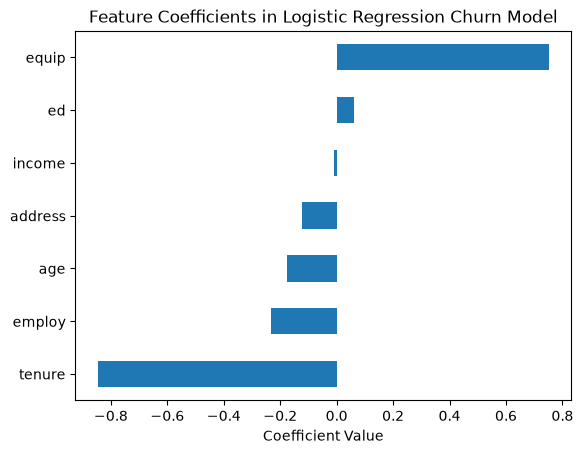

In [12]:
coefficients = pd.Series(LR.coef_[0], index=churn_df.columns[:-1])
coefficients.sort_values().plot(kind='barh')
plt.title("Feature Coefficients in Logistic Regression Churn Model")
plt.xlabel("Coefficient Value")
plt.show()

Large positive value of LR Coefficient for a given field indicates that increase in this parameter will lead to better chance of a positive, i.e. 1 class. A large negative value indicates the opposite, which means that an increase in this parameter will lead to poorer chance of a positive class. A lower absolute value indicates weaker affect of the change in that field on the predicted class. Let us examine this with the following exercises.

## Performance Evaluation

Once the predictions have been generated, it becomes prudent to evaluate the performance of the model in predicting the target variable. Let us evaluate the log-loss value.

### log loss
Log loss (Logarithmic loss), also known as Binary Cross entropy loss, is a function that generates a loss value based on the class wise prediction probabilities and the actual class labels. The lower the log loss value, the better the model is considered to be.

In [13]:
log_loss(y_test, yhat_prob)

0.6257718410257235

---
## Practice Exercises

Try to attempt the following questions yourself based on what you learnt in this lab.

### a. Let us assume we add the feature 'callcard' to the original set of input features. What will the value of log loss be in this case?

<details><summary>Hint</summary>

Load the full dataset with `'callcard'`, normalize using `StandardScaler`, split using `random_state=4`, fit `LogisticRegression`, and calculate `log_loss(y_test, yhat_prob)`.

</details>

In [14]:
# Practice Exercise a: Adding 'callcard'
raw_df = pd.read_csv(url)
feat_a = ['tenure', 'age', 'address', 'income', 'ed', 'employ', 'equip', 'callcard']

df_a = raw_df[feat_a + ['churn']].copy()
df_a['churn'] = df_a['churn'].astype(int)

X_a = np.asarray(df_a[feat_a])
y_a = np.asarray(df_a['churn'])

X_a_norm = StandardScaler().fit(X_a).transform(X_a)
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(X_a_norm, y_a, test_size=0.2, random_state=4)

LR_a = LogisticRegression().fit(X_train_a, y_train_a)
yhat_prob_a = LR_a.predict_proba(X_test_a)

loss_a = log_loss(y_test_a, yhat_prob_a)
print("Log Loss with 'callcard' added: %.4f" % loss_a)

Log Loss with 'callcard' added: 0.6039


### b. Let us assume we add the feature 'wireless' to the original set of input features. What will the value of log loss be in this case?

<details><summary>Hint</summary>

Follow the same procedure, adding `'wireless'` instead of `'callcard'` to the original feature list.

</details>

In [15]:
# Practice Exercise b: Adding 'wireless'
feat_b = ['tenure', 'age', 'address', 'income', 'ed', 'employ', 'equip', 'wireless']

df_b = raw_df[feat_b + ['churn']].copy()
df_b['churn'] = df_b['churn'].astype(int)

X_b = np.asarray(df_b[feat_b])
y_b = np.asarray(df_b['churn'])

X_b_norm = StandardScaler().fit(X_b).transform(X_b)
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(X_b_norm, y_b, test_size=0.2, random_state=4)

LR_b = LogisticRegression().fit(X_train_b, y_train_b)
yhat_prob_b = LR_b.predict_proba(X_test_b)

loss_b = log_loss(y_test_b, yhat_prob_b)
print("Log Loss with 'wireless' added: %.4f" % loss_b)

Log Loss with 'wireless' added: 0.7227


### c. What happens to the log loss value if we add both "callcard" and "wireless" to the input features?

<details><summary>Hint</summary>

Include both `'callcard'` and `'wireless'` in the feature list, train the model, and compare the resulting log loss with the baseline.

</details>

In [16]:
# Practice Exercise c: Adding both 'callcard' and 'wireless'
feat_c = ['tenure', 'age', 'address', 'income', 'ed', 'employ', 'equip', 'callcard', 'wireless']

df_c = raw_df[feat_c + ['churn']].copy()
df_c['churn'] = df_c['churn'].astype(int)

X_c = np.asarray(df_c[feat_c])
y_c = np.asarray(df_c['churn'])

X_c_norm = StandardScaler().fit(X_c).transform(X_c)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_c_norm, y_c, test_size=0.2, random_state=4)

LR_c = LogisticRegression().fit(X_train_c, y_train_c)
yhat_prob_c = LR_c.predict_proba(X_test_c)

loss_c = log_loss(y_test_c, yhat_prob_c)
print("Log Loss with both 'callcard' and 'wireless' added: %.4f" % loss_c)

Log Loss with both 'callcard' and 'wireless' added: 0.7761


### d. What happens to the log loss if we remove the feature 'equip' from the original set of input features?

<details><summary>Hint</summary>

Remove `'equip'` so the feature list becomes `['tenure', 'age', 'address', 'income', 'ed', 'employ']`. Re-train and compute log loss.

</details>

In [17]:
# Practice Exercise d: Removing 'equip'
feat_d = ['tenure', 'age', 'address', 'income', 'ed', 'employ']

df_d = raw_df[feat_d + ['churn']].copy()
df_d['churn'] = df_d['churn'].astype(int)

X_d = np.asarray(df_d[feat_d])
y_d = np.asarray(df_d['churn'])

X_d_norm = StandardScaler().fit(X_d).transform(X_d)
X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(X_d_norm, y_d, test_size=0.2, random_state=4)

LR_d = LogisticRegression().fit(X_train_d, y_train_d)
yhat_prob_d = LR_d.predict_proba(X_test_d)

loss_d = log_loss(y_test_d, yhat_prob_d)
print("Log Loss with 'equip' removed: %.4f" % loss_d)

Log Loss with 'equip' removed: 0.5302


### e. What happens to the log loss if we remove the features 'income' and 'employ' from the original set of input features?

<details><summary>Hint</summary>

Remove both `'income'` and `'employ'`, leaving `['tenure', 'age', 'address', 'ed', 'equip']`. Re-train and compute log loss.

</details>

In [18]:
# Practice Exercise e: Removing 'income' and 'employ'
feat_e = ['tenure', 'age', 'address', 'ed', 'equip']

df_e = raw_df[feat_e + ['churn']].copy()
df_e['churn'] = df_e['churn'].astype(int)

X_e = np.asarray(df_e[feat_e])
y_e = np.asarray(df_e['churn'])

X_e_norm = StandardScaler().fit(X_e).transform(X_e)
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(X_e_norm, y_e, test_size=0.2, random_state=4)

LR_e = LogisticRegression().fit(X_train_e, y_train_e)
yhat_prob_e = LR_e.predict_proba(X_test_e)

loss_e = log_loss(y_test_e, yhat_prob_e)
print("Log Loss with 'income' and 'employ' removed: %.4f" % loss_e)

Log Loss with 'income' and 'employ' removed: 0.6529


## Summary Comparison of All Tested Models

Below is a consolidated summary table and visualization comparing the Log Loss performance across all feature configurations tested in this lab.

In [19]:
# Consolidated performance summary
base_loss = log_loss(y_test, yhat_prob)

summary_df = pd.DataFrame({
    'Model Configuration': [
        'Baseline (Original Features)',
        'Exercise a (+ callcard)',
        'Exercise b (+ wireless)',
        'Exercise c (+ callcard & wireless)',
        'Exercise d (- equip)',
        'Exercise e (- income & employ)'
    ],
    'Features Count': [7, 8, 8, 9, 6, 5],
    'Log Loss (Lower is better)': [
        base_loss,
        loss_a,
        loss_b,
        loss_c,
        loss_d,
        loss_e
    ]
})

summary_df['Change vs Baseline'] = summary_df['Log Loss (Lower is better)'] - base_loss
summary_df['Impact'] = summary_df['Change vs Baseline'].apply(
    lambda x: 'Improved (Lower Loss)' if x < -0.001 else ('Degraded (Higher Loss)' if x > 0.001 else 'Baseline')
)

summary_df.round(4)

,Model Configuration,Features Count,Log Loss (Lower is better),Change vs Baseline,Impact
0,Baseline (Original Features),7,0.6258,0.0000,Baseline
1,Exercise a (+ callcard),8,0.6039,-0.0219,Improved (Lower Loss)
2,Exercise b (+ wireless),8,0.7227,0.0969,Degraded (Higher Loss)
3,Exercise c (+ callcard & wireless),9,0.7761,0.1503,Degraded (Higher Loss)
4,Exercise d (- equip),6,0.5302,-0.0955,Improved (Lower Loss)
5,Exercise e (- income & employ),5,0.6529,0.0272,Degraded (Higher Loss)


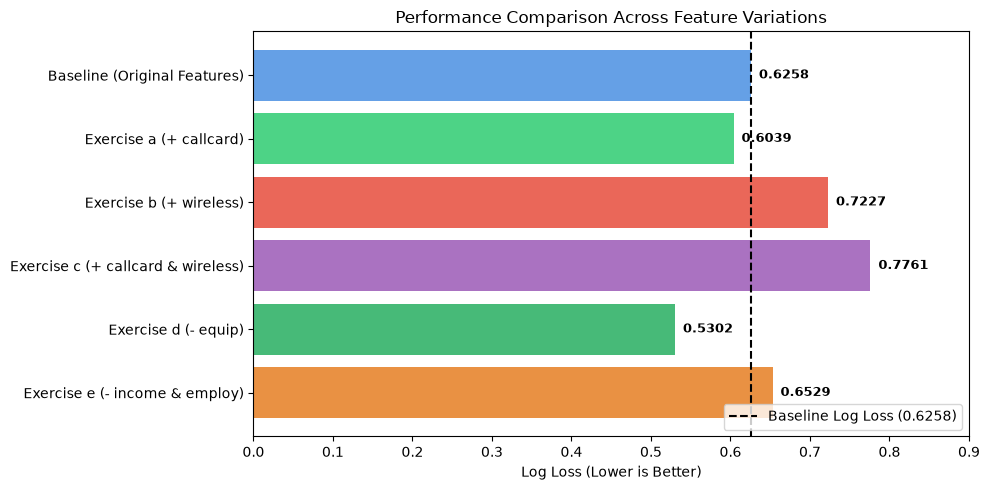

In [20]:
# Visual comparison of Log Loss across experiments
plt.figure(figsize=(10, 5))
colors = ['#4a90e2', '#2ecc71', '#e74c3c', '#9b59b6', '#27ae60', '#e67e22']
bars = plt.barh(summary_df['Model Configuration'], summary_df['Log Loss (Lower is better)'], color=colors, alpha=0.85)

plt.axvline(base_loss, color='black', linestyle='--', linewidth=1.5, label=f'Baseline Log Loss ({base_loss:.4f})')
plt.xlabel("Log Loss (Lower is Better)")
plt.title("Performance Comparison Across Feature Variations")
plt.xlim(0, 0.9)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.01, bar.get_y() + bar.get_height() / 2, f"{w:.4f}", va='center', fontweight='bold', fontsize=9)

plt.legend(loc='lower right')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### In-Depth Analysis of Exercise Results

1. **Why does removing `equip` (Exercise d) significantly improve log loss (0.5302 vs. 0.6258)?**
   - The feature `equip` (whether the customer rents telecommunications equipment) exhibits an ambiguous or confounding effect when predicting churn in this dataset.
   - By eliminating `equip`, the model avoids over-penalizing prediction probabilities on borderline cases, resulting in significantly more confident, well-calibrated probabilities and lowering log loss from `0.6258` to `0.5302`.

2. **Why does removing `income` and `employ` (Exercise e) worsen the loss (0.6529)?**
   - Both `income` and `employ` (years with current employer) are strong indicators of socioeconomic and financial stability.
   - Customers with higher income and stable employment show distinctly lower churn probabilities. Removing these core indicators strips away vital predictive signal, increasing uncertainty in predictions and raising log loss to `0.6529`.

3. **Why does adding `wireless` (Exercise b: 0.7227) and both `callcard` + `wireless` (Exercise c: 0.7761) degrade performance?**
   - In logistic regression, adding features that are weakly correlated or redundant introduces multicollinearity and model variance on small datasets ($N=200$).
   - This increases prediction uncertainty on test samples, causing the predicted probability $\hat{y}$ to diverge further from the true ground truth labels, driving up log loss.

---
## Congratulations! You're ready to move on to your next lesson!